# Command line: `mllm-shap`

**Business context:** not every team writes Python. The `mllm-shap` command turns a YAML configuration and a snapshot JSON file into a JSON result and a chart, and its exit codes let CI jobs tell a bad input from an unavailable model.

**Goal:** every subcommand and exit code: `config --example` / `--check`, `plugins`, `explain` (`--out`, `--render` / `--png`, `--log-level`), `reanalyze --strict`, and the exit codes 0, 2 (invalid input) and 3 (backend unavailable).

**Prerequisites:** `mllm-shap`, Python 3.12; the PNG chart needs the `[viz]` extra. Commands run in a temporary folder through `python -m mllm_shap.cli`, the module behind the `mllm-shap` script; in a terminal type `mllm-shap ...` instead.

**Expected output:** a configuration skeleton, the plugin list, a JSON result whose values add up to `grand_value - base_value`, a bar chart, a reanalyzed result with the same values, and one line per refused input with its exit code.

In [1]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path

from IPython.display import Image

from mllm_shap import ConversationSnapshot, Message, Role, Turn

In [2]:
WORKDIR = Path(tempfile.mkdtemp(prefix="mllm-shap-cli-"))
REPO_CONFIG = next(
    (
        path / "config"
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    Path.cwd() / "config",
)


def mllm_shap(*args: str) -> None:
    """Run ``mllm-shap <args>`` in WORKDIR and print its output and exit code.

    Paths under the repository's ``config/`` folder are printed relative to it.
    """
    completed = subprocess.run(
        [sys.executable, "-m", "mllm_shap.cli", *args],
        capture_output=True,
        text=True,
        cwd=WORKDIR,
        check=False,
    )
    for stream in (completed.stdout, completed.stderr):
        print(stream.replace(str(REPO_CONFIG), "config"), end="")
    print(f"[exit {completed.returncode}]")

## Usage

`mllm-shap --help` lists the four subcommands; each has its own `--help`.

In [3]:
mllm_shap("--help")

usage: mllm-shap [-h] [--log-level {debug,info,warning,error}]
                 {explain,reanalyze,plugins,config} ...

Shapley-value attributions for conversational language models.

positional arguments:
  {explain,reanalyze,plugins,config}
    explain             explain one snapshot
    reanalyze           rescore an archived run without backend calls
    plugins             list registered plugins
    config              print or check a configuration

options:
  -h, --help            show this help message and exit
  --log-level {debug,info,warning,error}
                        log mllm_shap events at this level to stderr
[exit 0]


## Write and check a configuration

**Business:** A configuration checked before it is committed fails in review, not in a nightly job.

**Technical:** `config --example` prints a commented skeleton with every section (the mock backend, `estimator: exact`, an archive under `./runs/{run_id}`). `config --check FILE` validates a file and exits with 0, or with 2 and the reason. The presets shipped in the repository's `config/` folder are checked the same way; the LM Studio, transformers and API presets need their extras and services only when a run starts, not to validate.

In [4]:
example = subprocess.run(
    [sys.executable, "-m", "mllm_shap.cli", "config", "--example"],
    capture_output=True,
    text=True,
    check=True,
).stdout
print(example)
# Explain the user's words only; the system prompt of the snapshot stays fixed.
example = example.replace(
    "plugin_options: {}", "plugin_options: {tokens: {roles: [user]}}"
)
(WORKDIR / "explain.yaml").write_text(example)
mllm_shap("config", "--check", "explain.yaml")
for preset in sorted(REPO_CONFIG.glob("dev_*.yaml")):
    mllm_shap("config", "--check", str(preset))
(WORKDIR / "partial_exact.yaml").write_text(
    example.replace("fraction: 1.0", "fraction: 0.5")
)
mllm_shap("config", "--check", "partial_exact.yaml")

# mllm-shap explain configuration. Validate with: mllm-shap config --check FILE
backend:
  kind: mock                # mock | api | lmstudio | transformers (or a plugin)
  model_id: mock            # model name passed to the backend
  # api_host: http://localhost:1234/v1   # api backend only
  timeout_s: 120.0          # per-request timeout of remote backends
  max_retries: 3            # retries after transient backend failures
  options: {}               # backend-specific settings (LM Studio: see docs)

generation:
  max_new_tokens: 32        # tokens generated per coalition
  temperature: 0.0          # 0.0 makes generations deterministic (enables dedup)
  top_k: 1
  compute_embeddings: false # set automatically for embedding value functions

explanation:
  estimand: shapley         # shapley | banzhaf
  estimator: exact          # exact | mc | complementary | neyman_cc
  value_fn: tfidf_cosine    # tfidf_cosine | embedding_cosine | logprob | ...
  normalizer: identity      # ident

explain.yaml: valid
[exit 0]


config/dev_api.yaml: valid
[exit 0]


config/dev_lmstudio.yaml: valid
[exit 0]


config/dev_transformers.yaml: valid
[exit 0]


mllm-shap: error: estimator 'exact' enumerates every coalition; set budget.fraction: 1.0
[exit 2]


## List the plugins

`plugins` prints every registered name per plugin group: the built-ins plus anything installed packages register through entry points (`plugins_extending.ipynb`). These are the names the configuration accepts.

In [5]:
mllm_shap("plugins")

mllm_shap.estimators: complementary, exact, kernel_banzhaf, leverage, loo, mc, neyman_cc, proxy
mllm_shap.estimands: banzhaf, shapley
mllm_shap.value_fns: bertscore, contrastive, embedding_cosine, judge_grade, logprob, nli_logodds, reference_wer, self_logprob, semascore, speech_bertscore, tf_jsd, tf_logprob, tfidf_cosine, transcribed
mllm_shap.normalizers: abs_sum, identity, min_max, power_shift
mllm_shap.backends: api, lmstudio, mock, mock_audio, transformers
mllm_shap.partitions: messages, sentences, sgpa_segments, tokens
mllm_shap.absence_policies: delete, neutral, pad
mllm_shap.renderers: token_bar, token_text
[exit 0]


## Explain a snapshot

**Business:** One command produces the artifact a reviewer needs: a JSON file with values, labels and the run manifest, plus an optional chart.

**Technical:** The snapshot file uses the `ConversationSnapshot.to_json` format. `explain --out` writes the same payload as `ExplainRunOutput.to_dict()`; `--render token_bar --png chart.png` saves a chart (both flags or neither); `--log-level info` prints the pipeline's stage events to stderr. The example configuration uses the mock backend, which answers with a hash of the prompt: only the full prompt reproduces the base answer, every other coalition scores 0 with `tfidf_cosine`, and exact Shapley splits the value equally between the six words.

In [6]:
SYSTEM = (
    "You are a support assistant for a store. Answer only from the question, in one "
    'short sentence. If it does not give enough information, say "Not enough '
    'information." Never invent policy details and never ask a question.'
)
snapshot = ConversationSnapshot.from_turns((
    Turn(
        messages=(
            Message(role=Role.SYSTEM, text=SYSTEM),
            Message(role=Role.USER, text="Refund within thirty days with receipt?"),
        )
    ),
))
(WORKDIR / "snapshot.json").write_text(snapshot.to_json())

456

2026-10-19 19:16:03,875 INFO [mllm_shap.pipeline.orchestrator] explain run 84caf96b080cfbe6-90716f5bfc5b started: 6 players, estimator exact, backend mock
2026-10-19 19:16:03,878 INFO [mllm_shap.pipeline.orchestrator] base generated in 0.1 ms
2026-10-19 19:16:03,878 INFO [mllm_shap.pipeline.orchestrator] 64 coalitions scheduled
2026-10-19 19:16:03,890 INFO [mllm_shap.pipeline.orchestrator] explain run 84caf96b080cfbe6-90716f5bfc5b done in 14.3 ms (64 coalitions, 63 backend calls)
[exit 0]
keys: ['values', 'labels', 'base_value', 'grand_value', 'estimand', 'metrics', 'manifest', 'perf']
   Refund 0.1667
   within 0.1667
   thirty 0.1667
     days 0.1667
     with 0.1667
 receipt? 0.1667
sum: 1.0  grand - base: 1.0
archive: ['84caf96b080cfbe6-90716f5bfc5b']


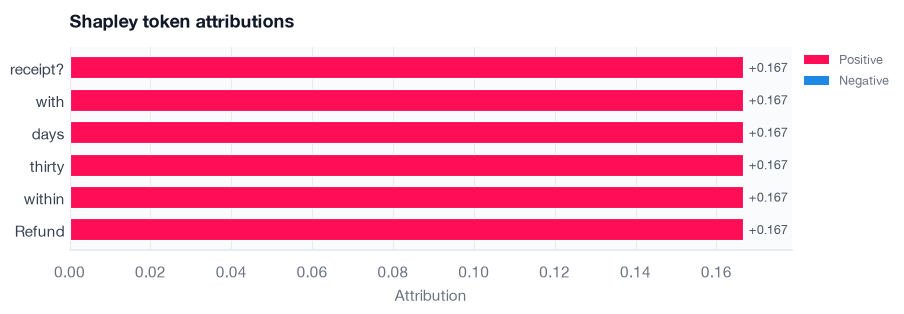

In [7]:
mllm_shap(
    "--log-level",
    "info",
    "explain",
    "--config",
    "explain.yaml",
    "--snapshot",
    "snapshot.json",
    "--out",
    "result.json",
    "--render",
    "token_bar",
    "--png",
    "chart.png",
)
result = json.loads((WORKDIR / "result.json").read_text())
print("keys:", list(result))
for label, value in zip(result["labels"], result["values"], strict=True):
    print(f"{label['text']:>9} {value:.4f}")
print(
    "sum:",
    round(sum(result["values"]), 6),
    " grand - base:",
    result["grand_value"] - result["base_value"],
)
print("archive:", sorted(path.name for path in (WORKDIR / "runs").iterdir()))
Image(WORKDIR / "chart.png")

## Reanalyze the archive

**Business:** Anyone with the archive folder and the configuration can reproduce the result file without model access.

**Technical:** The example configuration archives the run under `./runs/{run_id}`. `reanalyze --archive` rescores it with no backend calls and prints (or writes with `--out`) the same JSON payload; the labels carry ids only because archives do not store the player text. `--strict` refuses archives scored with backend embeddings (`archive_reanalyze.ipynb`); this run used none, so it succeeds.

In [8]:
run_dir = f"runs/{result['manifest']['run_id']}"
mllm_shap(
    "reanalyze",
    "--config",
    "explain.yaml",
    "--archive",
    run_dir,
    "--strict",
    "--out",
    "replay.json",
)
replay = json.loads((WORKDIR / "replay.json").read_text())
print("same values as explain:", replay["values"] == result["values"])
print("executed backend calls:", replay["metrics"]["executed"])

[exit 0]
same values as explain: True
executed backend calls: 0


## Exit codes

**Business:** A scheduler can retry exit code 3 (the model server is down) and page a human for exit code 2 (the input is wrong).

**Technical:** Every input the command reads is checked: a missing or malformed snapshot, an invalid configuration, a damaged archive and `--render` without `--png` exit with 2 and one `mllm-shap: error:` line. A backend that cannot be built or reached exits with 3: here an `api` backend pointed at a closed local port with `max_retries: 0` (with the `[api]` extra missing, the same configuration also exits with 3). Any other exception is a bug and propagates with its traceback.

In [9]:
(WORKDIR / "broken.json").write_text(
    '{"turns": [{"messages": [{"role": "robot", "text": "hi"}]}]}'
)
mllm_shap("explain", "--config", "explain.yaml", "--snapshot", "missing.json")
mllm_shap("explain", "--config", "explain.yaml", "--snapshot", "broken.json")
mllm_shap("explain", "--config", "partial_exact.yaml", "--snapshot", "snapshot.json")
mllm_shap(
    "explain",
    "--config",
    "explain.yaml",
    "--snapshot",
    "snapshot.json",
    "--render",
    "token_text",
)
(WORKDIR / run_dir / "manifest.json").unlink()
mllm_shap("reanalyze", "--config", "explain.yaml", "--archive", run_dir)

(WORKDIR / "unreachable.yaml").write_text(
    example
    .replace("kind: mock ", "kind: api  ")
    .replace("# api_host: http://localhost:1234/v1", "api_host: http://127.0.0.1:9/v1")
    .replace("max_retries: 3 ", "max_retries: 0 ")
    .replace("path: ./runs/{run_id}", 'path: ""            ')
)
mllm_shap("explain", "--config", "unreachable.yaml", "--snapshot", "snapshot.json")

mllm-shap: error: cannot read snapshot missing.json: No such file or directory
[exit 2]


mllm-shap: error: invalid snapshot broken.json: turn 0: unknown role 'robot'
[exit 2]


mllm-shap: error: estimator 'exact' enumerates every coalition; set budget.fraction: 1.0
[exit 2]


mllm-shap: error: --render and --png must be given together
[exit 2]


mllm-shap: error: cannot read archive runs/84caf96b080cfbe6-90716f5bfc5b: archive manifest missing: runs/84caf96b080cfbe6-90716f5bfc5b/manifest.json
[exit 2]


mllm-shap: error: backend unavailable: HTTP API generation request failed
[exit 3]
